In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt 
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error
from sklearn.svm import SVR

In [2]:
# Set random seed for reproducibility of random data
np.random.seed(42)

In [3]:
# Generate synthetic dataset: 100 days with random walk prices
num_data_points = 100
days = np.arange(1, num_data_points + 1)  # Create array of days (1 to 100)
r = np.random.randn(num_data_points)  # Generate random noise
prices = 100 + np.cumsum(r)  # Simulate prices starting at 100 with cumulative noise

In [4]:
# Create DataFrame with days and prices columns
data = pd.DataFrame({"days": days, "prices": prices})

In [5]:
# Convert days to float for consistency in processing
data["days"] = data["days"].astype(float)

In [6]:
# Define features (X) and target variable (y)
X = data[["days"]]  # Feature: days as input
y = data["prices"]  # Target: prices as output

In [7]:
# Split data into 80% training and 20% testing sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [8]:
# Scale features to [0, 1] range for better model performance
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)  # Fit and transform training data
X_test_scaled = scaler.transform(X_test)  # Transform testing data using same scaler

In [9]:
# Initialize and train SVR model with linear kernel
model = SVR(kernel='linear')
model.fit(X_train_scaled, y_train)  # Train model on scaled training data

SVR(kernel='linear')

In [10]:
# Make predictions on training and testing sets
y_pred_train = model.predict(X_train_scaled)  # Predict for training data
y_pred_test = model.predict(X_test_scaled)  # Predict for testing data

In [11]:
# Calculate Mean Squared Error to evaluate model performance
mse_train = mean_squared_error(y_train, y_pred_train)  # MSE for training set
mse_test = mean_squared_error(y_test, y_pred_test)  # MSE for testing set

In [12]:
# Predict prices for the next 10 days (days 101 to 110)
new_days = np.arange(num_data_points + 1, num_data_points + 11)  # Create future days
new_days_df = pd.DataFrame({"days": new_days})  # Create DataFrame for new days
new_days_scaled = scaler.transform(new_days_df)  # Scale new days using same scaler
new_price = model.predict(new_days_scaled)  # Predict prices for future days

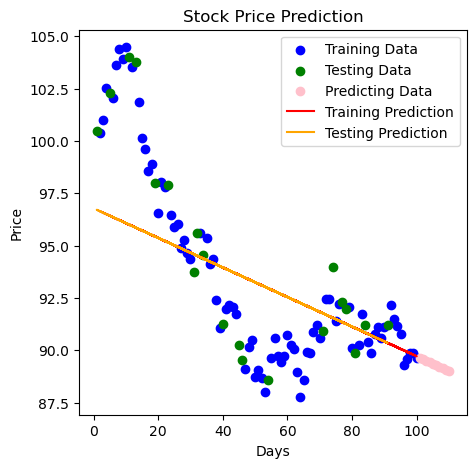

In [13]:
# Visualize data and predictions
plt.figure(figsize=(5, 5))  # Set plot size to 5x5 inches
plt.scatter(X_train, y_train, color='blue', label='Training Data')  # Plot training data
plt.scatter(X_test, y_test, color='green', label='Testing Data')  # Plot testing data
plt.scatter(new_days, new_price, color='pink', label='Predicting Data')  # Plot predicted future prices
plt.plot(X_train, y_pred_train, color='red', label='Training Prediction')  # Plot training predictions
plt.plot(X_test, y_pred_test, color='orange', label='Testing Prediction')  # Plot testing predictions
plt.xlabel('Days')  # Label x-axis
plt.ylabel('Price')  # Label y-axis
plt.title('Stock Price Prediction')  # Set plot title
plt.legend()  # Show legend
plt.show()  # Display the plot